# Lab 2 - Sentinel PDF + steganography

I look at histograms of Sentinel-2 and Sentinel-1 for urban and natural areas.
Then I change 2 LSBs in one image and check if you can see it / detect it.
Optional: small compressive sensing test.


## Imports


In [1]:
import json
from pathlib import Path
import matplotlib.pyplot as plt
import numpy as np
import rasterio

%matplotlib inline


## Load function

Just reading geotiff bands from the data folder.


In [2]:
def load_tif(path):
    with rasterio.open(path) as src:
        return src.read(1).astype(np.float32)

data = Path('data')


## Sentinel-2 urban and natural

I take B02, B03, B04, B08.
Urban = around Warsaw, natural = forest near Bialowieza.


urban
S2A_34UDC_20230815_0_L2A 2023-08-15T09:56:17.485000Z
B02 mean 594.9 std 493.4
B03 mean 748.0 std 506.5
B04 mean 745.4 std 571.3
B08 mean 1781.8 std 836.0


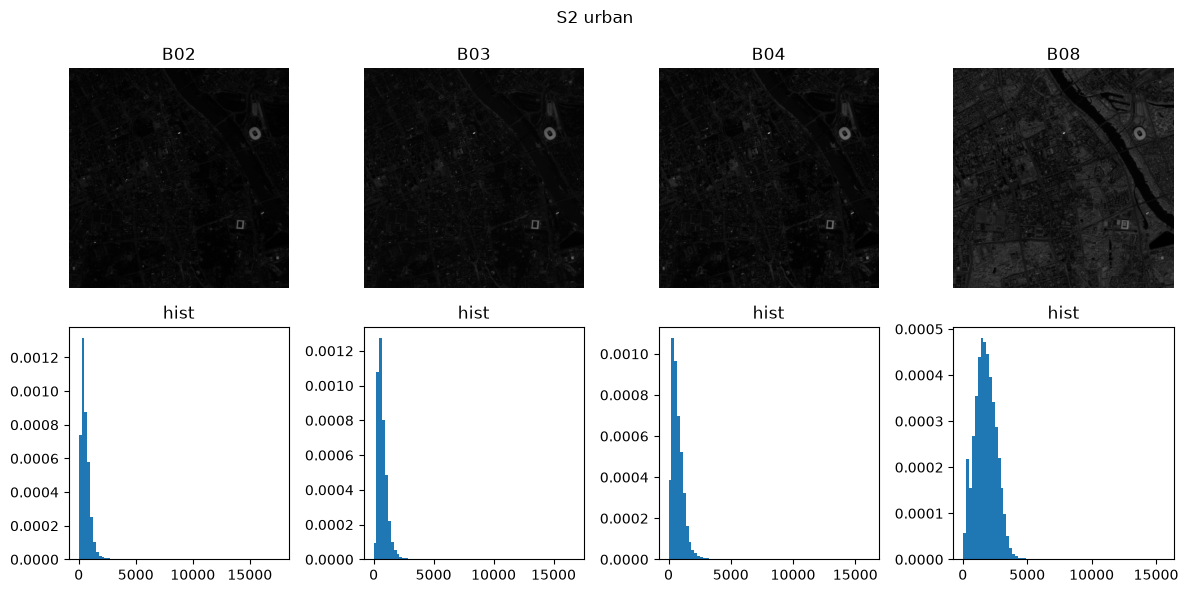

natural
S2A_34UFD_20230710_0_L2A 2023-07-10T09:36:00.727000Z
B02 mean 225.9 std 125.7
B03 mean 427.6 std 169.3
B04 mean 260.7 std 232.6
B08 mean 3365.9 std 554.9


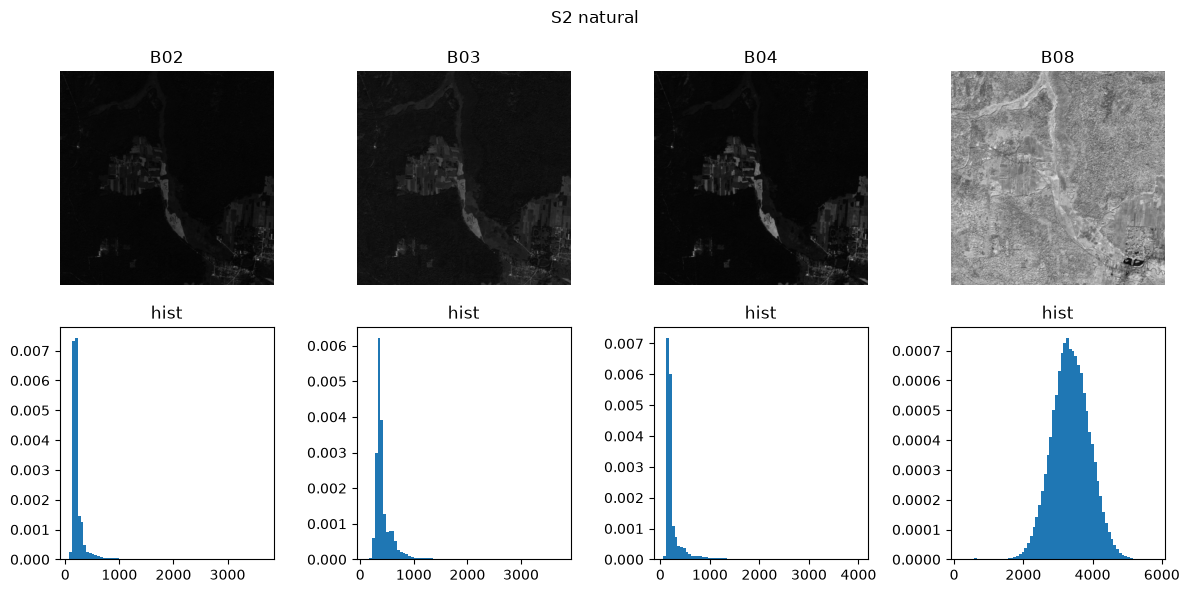

In [3]:
bands = ['B02', 'B03', 'B04', 'B08']

for area in ['urban', 'natural']:
    print(area)
    folder = data / ('s2_' + area)
    meta = json.load(open(folder / 'meta.json'))
    print(meta['item_id'], meta.get('datetime'))

    fig, axes = plt.subplots(2, 4, figsize=(12, 6))
    for i, b in enumerate(bands):
        img = load_tif(folder / (b + '.tif'))
        print(b, 'mean', round(float(img.mean()),1), 'std', round(float(img.std()),1))
        axes[0, i].imshow(img, cmap='gray')
        axes[0, i].set_title(b)
        axes[0, i].axis('off')
        axes[1, i].hist(img.ravel(), bins=70, density=True)
        axes[1, i].set_title('hist')
    plt.suptitle('S2 ' + area)
    plt.tight_layout()
    plt.show()


### My observations (S2)

Urban hist is more spread out. Makes sense because city has buildings, roads, different materials.

Natural/forest looks more concentrated in visible bands and B08 (NIR) is high because plants reflect a lot in NIR.

So from PDF alone you can already see that these are different land covers.


## Sentinel-1 same places

VV and VH. I plot also in dB because the values are weird on linear scale.


urban
S1A_IW_GRDH_1SDV_20230830T044443_20230830T044508_050100_06075F
VV mean 326.2 std 607.9
VH mean 158.4 std 202.2


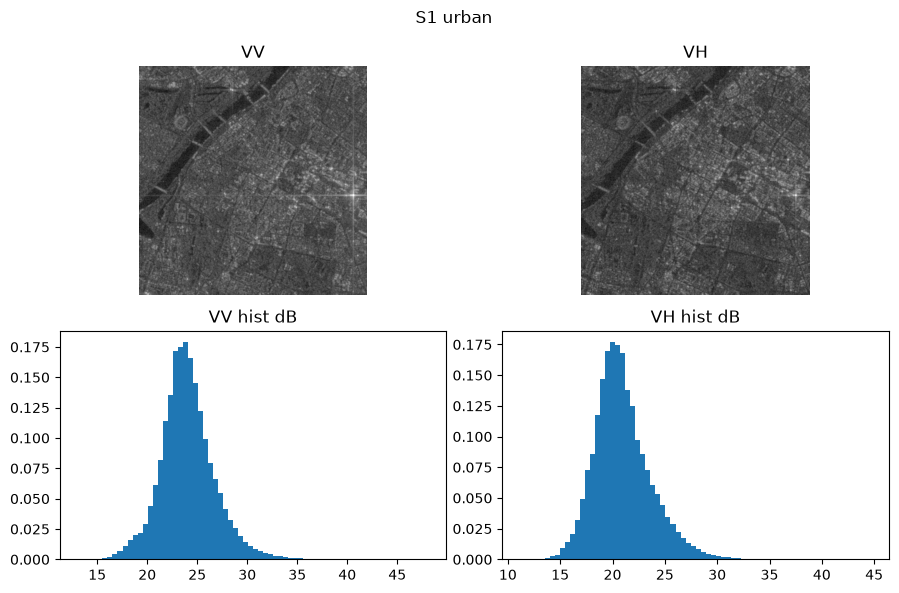

natural
S1A_IW_GRDH_1SDV_20230830T044443_20230830T044508_050100_06075F
VV mean 250.6 std 106.5
VH mean 126.5 std 36.3


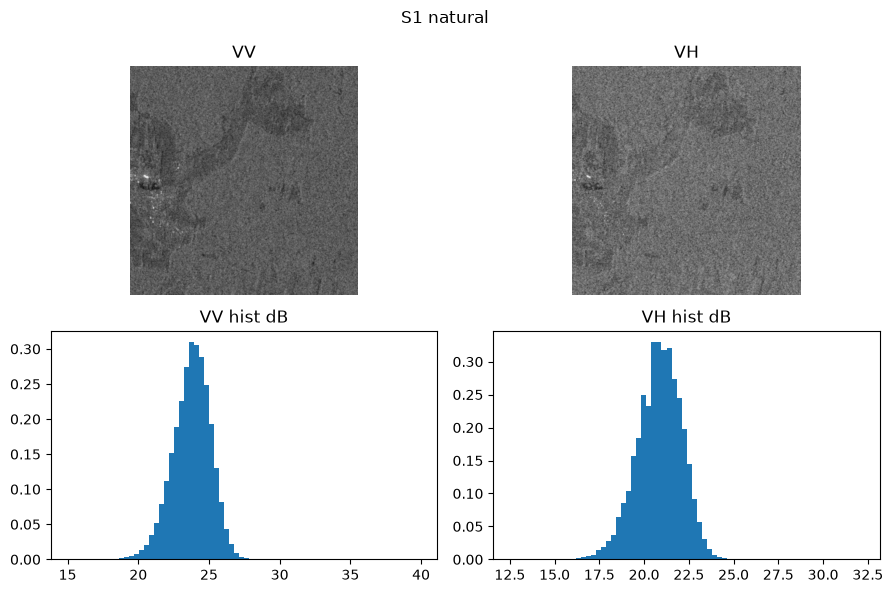

In [4]:
for area in ['urban', 'natural']:
    print(area)
    folder = data / ('s1_' + area)
    meta = json.load(open(folder / 'meta.json'))
    print(meta['item_id'])

    fig, axes = plt.subplots(2, 2, figsize=(9, 6))
    for i, pol in enumerate(['VV', 'VH']):
        img = load_tif(folder / (pol + '.tif'))
        img_db = 10 * np.log10(np.maximum(img, 1))
        print(pol, 'mean', round(float(img.mean()),1), 'std', round(float(img.std()),1))
        axes[0, i].imshow(img_db, cmap='gray')
        axes[0, i].set_title(pol)
        axes[0, i].axis('off')
        axes[1, i].hist(img_db.ravel(), bins=70, density=True)
        axes[1, i].set_title(pol + ' hist dB')
    plt.suptitle('S1 ' + area)
    plt.tight_layout()
    plt.show()


### My observations (S1)

Urban has bigger std, more bright spots. Probably buildings / double bounce.

Natural is smoother. Less crazy values.

S1 is radar so no clouds problem. It measures structure more than color, so its a nice complement to S2.


## Steganography

I take urban B04, convert to 8 bit, replace last 2 bits with random numbers.


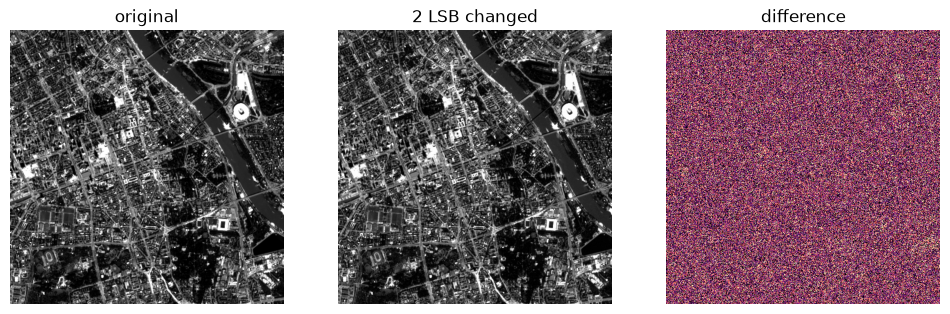

max difference = 3


In [5]:
rng = np.random.default_rng(0)

img = load_tif(data / 's2_urban' / 'B04.tif')
lo, hi = np.percentile(img, (2, 98))
img8 = np.clip((img - lo) / (hi - lo + 1e-6) * 255, 0, 255).astype(np.uint8)

rand_bits = rng.integers(0, 4, size=img8.shape, dtype=np.uint8)
changed = (img8 & 252) | rand_bits

plt.figure(figsize=(12,4))
plt.subplot(1,3,1)
plt.imshow(img8, cmap='gray')
plt.title('original')
plt.axis('off')
plt.subplot(1,3,2)
plt.imshow(changed, cmap='gray')
plt.title('2 LSB changed')
plt.axis('off')
plt.subplot(1,3,3)
plt.imshow(np.abs(changed.astype(int) - img8.astype(int)), cmap='magma')
plt.title('difference')
plt.axis('off')
plt.show()

print('max difference =', int(np.abs(changed.astype(int) - img8.astype(int)).max()))


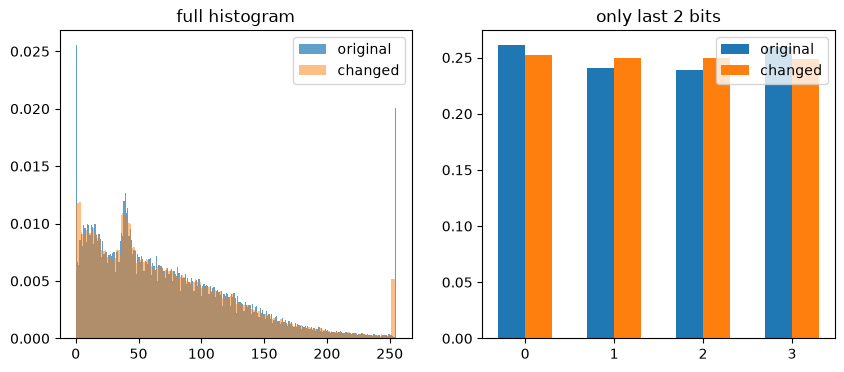

In [6]:
plt.figure(figsize=(10,4))
plt.subplot(1,2,1)
plt.hist(img8.ravel(), bins=256, range=(0,255), density=True, alpha=0.7, label='original')
plt.hist(changed.ravel(), bins=256, range=(0,255), density=True, alpha=0.5, label='changed')
plt.title('full histogram')
plt.legend()

plt.subplot(1,2,2)
a = np.bincount(img8.ravel() & 3, minlength=4)
b = np.bincount(changed.ravel() & 3, minlength=4)
x = np.arange(4)
plt.bar(x-0.15, a/a.sum(), width=0.3, label='original')
plt.bar(x+0.15, b/b.sum(), width=0.3, label='changed')
plt.xticks(x)
plt.title('only last 2 bits')
plt.legend()
plt.show()


### Answers

Does it affect visual quality?  
Basically no. Images look the same. Max change is only 3.

Do histograms look different?  
Normal full histogram almost same. But if I look only at last 2 bits, after random replace it becomes almost flat/uniform.

Can this detect manipulated satellite images?  
A bit yes, because natural images usually dont have perfectly random LSBs. But its weak alone. Compression etc can mess this up. Better use more checks, not only this.


## Optional - compressive sensing

I tried a small version of the idea from Basic_opt notebook.


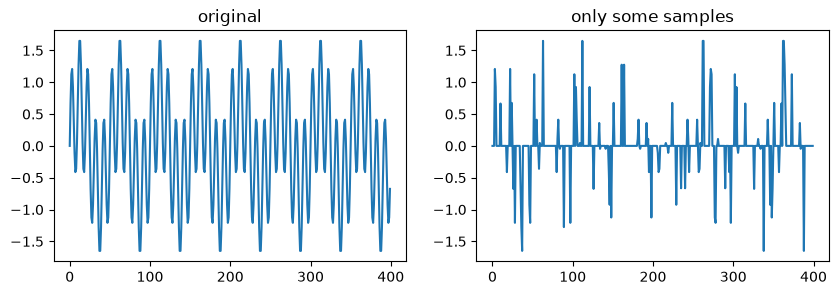

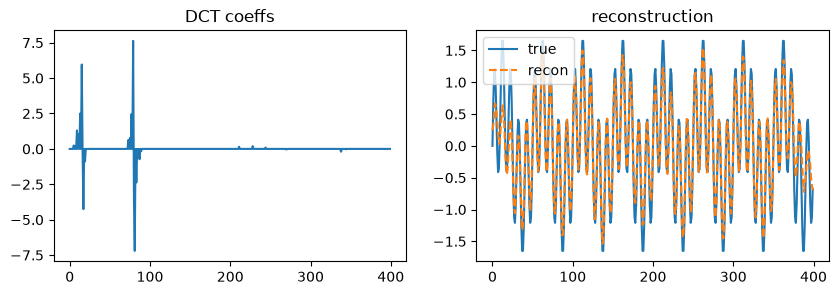

error = 0.28


In [7]:
from scipy import fftpack

N = 400
t = np.arange(N)
signal = np.sin(2*np.pi*t/10) + 0.7*np.sin(2*np.pi*t/50)

m = 100
mask = np.zeros(N)
mask[rng.choice(N, size=m, replace=False)] = 1
y = signal * mask

plt.figure(figsize=(10,3))
plt.subplot(1,2,1)
plt.plot(signal)
plt.title('original')
plt.subplot(1,2,2)
plt.plot(y)
plt.title('only some samples')
plt.show()

X = np.zeros(N)
lam = 0.08
step = 0.4
for i in range(250):
    xt = fftpack.idct(X, norm='ortho')
    g = fftpack.dct((xt - signal) * mask, norm='ortho')
    Z = X - step * g
    X = np.sign(Z) * np.maximum(np.abs(Z) - lam, 0)

recon = fftpack.idct(X, norm='ortho')

plt.figure(figsize=(10,3))
plt.subplot(1,2,1)
plt.plot(X)
plt.title('DCT coeffs')
plt.subplot(1,2,2)
plt.plot(signal, label='true')
plt.plot(recon, '--', label='recon')
plt.legend()
plt.title('reconstruction')
plt.show()

print('error =', round(float(np.linalg.norm(signal-recon)/np.linalg.norm(signal)), 3))


### Where CS can be useful in EO

Maybe when satellite cannot send all data (bandwidth).
Or when some samples are missing.
Or for sparse SAR type problems.

If signal is sparse in some transform, you can reconstruct from fewer measurements. Not always practical, but the idea is useful.
